### Author: John Crumlish

In [1]:
import pandas as pd

In [ ]:
# read the CSV file
datadir = "../data/"
filename = datadir + "mly4935.csv"

In [ ]:
# read the CSV file and skip the intro information
df = pd.read_csv(filename, skiprows=19)

df.head(5)

,year,month,meant,maxtp,mintp,mnmax,mnmin,rain,gmin,wdsp,maxgt,sun
0,1996,8,13.4,20.4,7.3,16.6,10.3,109.4,5.3,8.3,34,
1,1996,10,9.7,,,12.5,7.0,,,,,
2,1996,11,5.0,,,7.6,2.5,,,,,
3,1996,12,3.1,10.7,-4.0,5.2,1.1,,-5.3,9.4,48,
4,1997,1,3.4,10.7,-3.9,5.2,1.6,26.0,-5.2,8.0,40,42.1


##### Creating a Date Column

In [ ]:
# create a day column and set every date to the first day of the month
df["day"] = 1
df.head(3)

,year,month,meant,maxtp,mintp,mnmax,mnmin,rain,gmin,wdsp,maxgt,sun,day
0,1996,8,13.4,20.4,7.3,16.6,10.3,109.4,5.3,8.3,34,,1
1,1996,10,9.7,,,12.5,7.0,,,,,,1
2,1996,11,5.0,,,7.6,2.5,,,,,,1


In [ ]:
# combine the year, month and day columns into a single date column
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

# Display the year, month and date columns
df[["year", "month", "day", "date"]].head(5)

,year,month,day,date
0,1996,8,1,1996-08-01
1,1996,10,1,1996-10-01
2,1996,11,1,1996-11-01
3,1996,12,1,1996-12-01
4,1997,1,1,1997-01-01


##### Plotting Temperature Data

[Text(0.5, 1.0, 'Mean Temperature at Knock Airport'),
 Text(0.5, 0, 'Date'),
 Text(0, 0.5, 'Temperature (°C)')]

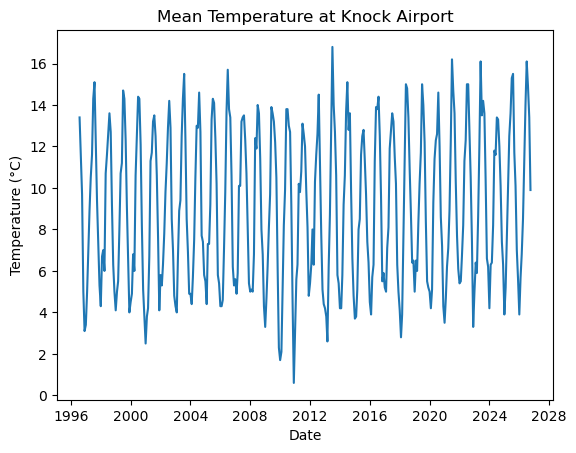

In [17]:
# import seaborn for plotting
import seaborn as sns

# plot mean temperature over time
sns.lineplot(data=df, x="date", y="meant").set(
    title="Mean Temperature at Knock Airport",
    xlabel="Date",
    ylabel="Temperature (°C)"
)

##### Plotting Mean Temperature For Each Month
[Groupby - W3Schools](https://www.w3schools.com/python/pandas/ref_df_groupby.asp)

[Seaborn Lineplots](https://seaborn.pydata.org/generated/seaborn.lineplot.html)

In [18]:
# calculate the average temperature for each month
monthly_mean = df.groupby("month")["meant"].mean()

monthly_mean

month
1      4.313333
2      4.816667
3      5.940000
4      7.926667
5     10.560000
6     12.700000
7     14.116667
8     13.987097
9     12.360000
10     9.509677
11     6.556667
12     4.810000
Name: meant, dtype: float64

[Text(0.5, 1.0, 'Average Monthly Temperature at Knock Airport'),
 Text(0.5, 0, 'Month'),
 Text(0, 0.5, 'Temperature (°C)')]

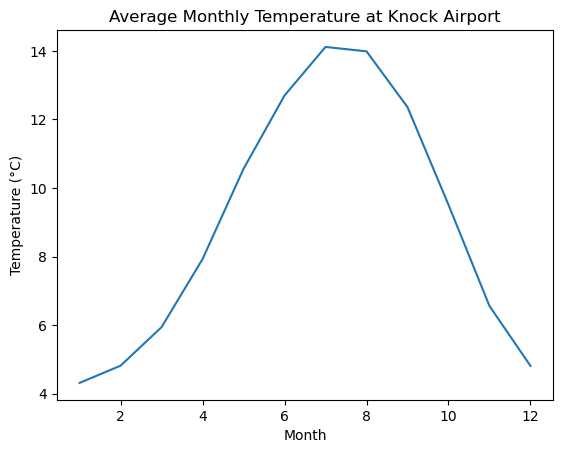

In [21]:
# plot the average temperature for each month
sns.lineplot(x=monthly_mean.index, y=monthly_mean).set(
    title="Average Monthly Temperature at Knock Airport",
    xlabel="Month",
    ylabel="Temperature (°C)"
)

##### Plotting Windspeed

In [ ]:
# check the windspeed column
print(df["wdsp"].describe())

count     362
unique     68
top       8.8
freq       18
Name: wdsp, dtype: object


In [26]:
# convert windspeed values to numbers
df["wdsp"] = pd.to_numeric(df["wdsp"], errors="coerce")

print(df["wdsp"].dtype)

float64


[Text(0.5, 1.0, 'Mean Windspeed at Knock Airport'),
 Text(0.5, 0, 'Date'),
 Text(0, 0.5, 'Windspeed (knots)')]

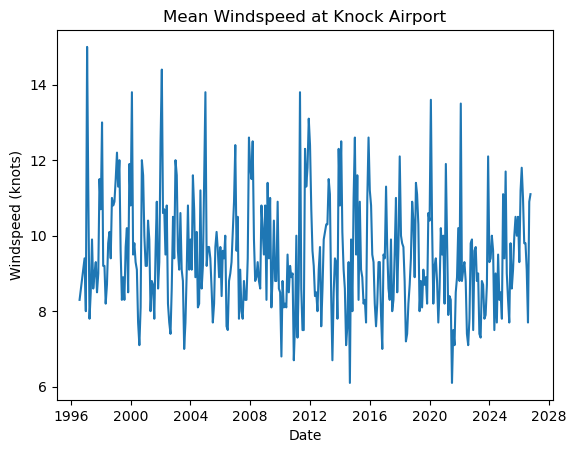

In [ ]:
# plot the mean windspeed
sns.lineplot(data=df, x="date", y="wdsp").set(
    title="Mean Windspeed at Knock Airport",
    xlabel="Date",
    ylabel="Windspeed (knots)"
)

##### Plotting Rolling Windspeed

[Text(0.5, 1.0, '12-Month Rolling Average Windspeed at Knock Airport'),
 Text(0.5, 0, 'Date'),
 Text(0, 0.5, 'Windspeed (knots)')]

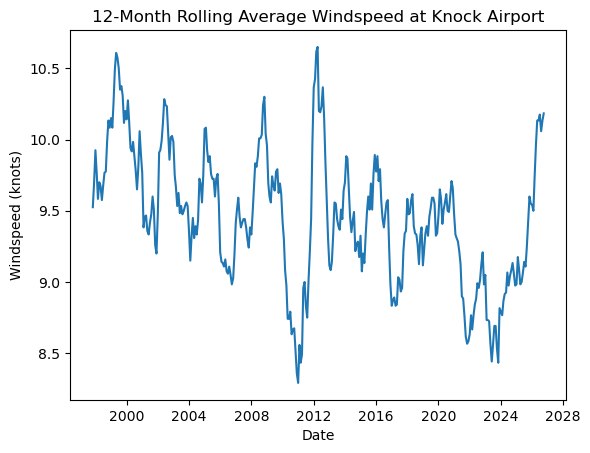

In [ ]:
# calculate the 12 month rolling average windspeed
df["rolling_wdsp"] = df["wdsp"].rolling(12).mean()

# plot the rolling average windspeed
sns.lineplot(data=df, x="date", y="rolling_wdsp").set(
    title="12-Month Rolling Average Windspeed at Knock Airport",
    xlabel="Date",
    ylabel="Windspeed (knots)"
)